# Anime Recommendation

This is a recommendation project.

The files are anime titles and user ratings. I will drop the unused rating code, look at the score distribution and popular titles, then train two models on the same split. The first is Truncated SVD. The second is a neural collaborative filter with embeddings. The deep model is the one I want here. I will compare RMSE and save the neural model.


In [1]:
import kagglehub

path = kagglehub.dataset_download("CooperUnion/anime-recommendations-database")
print("Path to dataset files:", path)


100%|██████████| 25.0M/25.0M [00:06<00:00, 3.84MB/s]

Extracting files...


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\CooperUnion\anime-recommendations-database\versions\1


In [2]:
import os
import glob
import pandas as pd

ratings_path = glob.glob(os.path.join(path, "**", "rating.csv"), recursive=True)[0]
ratings = pd.read_csv(ratings_path)
ratings = ratings.query("rating >= 0")
ratings = ratings.sample(n=200000, random_state=42)
ratings.head()


,user_id,anime_id,rating
5656992,53103,6707,7
3552500,32884,339,8
2636208,24907,23755,9
5554182,52213,10156,7
95779,994,1562,10


In [3]:
print(ratings.shape)
print(ratings["rating"].value_counts().sort_index())


(200000, 3)
rating
1       543
2       720
3      1266
4      3239
5      9046
6     20000
7     43269
8     51947
9     39951
10    30019
Name: count, dtype: int64


In [4]:
anime_path = glob.glob(os.path.join(path, "**", "anime.csv"), recursive=True)[0]
anime = pd.read_csv(anime_path)
ratings = ratings.merge(anime[["anime_id", "name"]], on="anime_id")
anime.head()


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


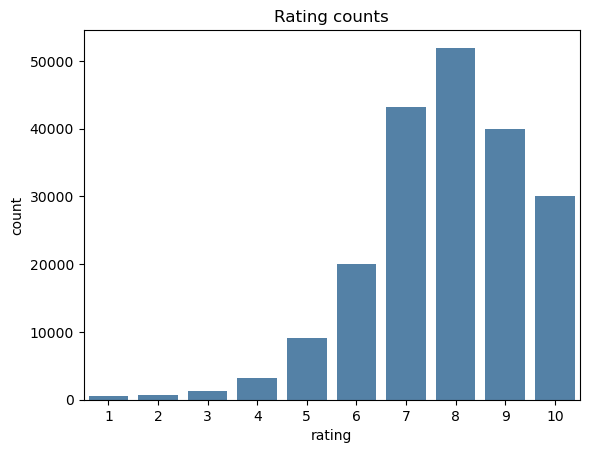

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=ratings, x="rating", color="steelblue")
plt.title("Rating counts")
plt.show()


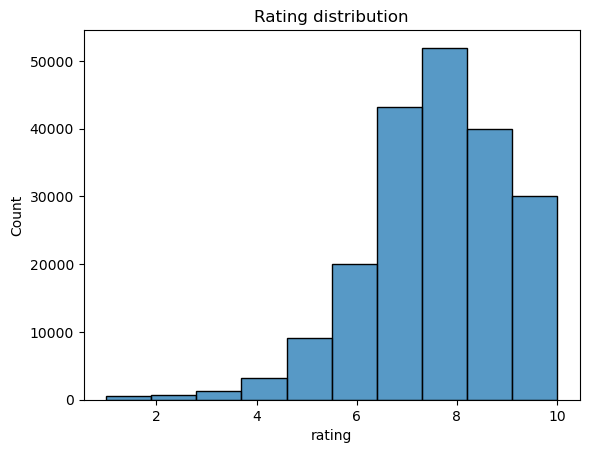

In [6]:
sns.histplot(data=ratings, x="rating", bins=10)
plt.title("Rating distribution")
plt.show()


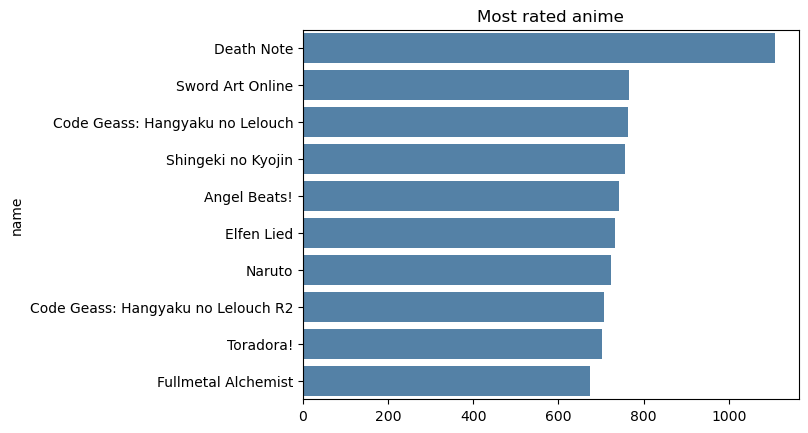

In [7]:
top = ratings["name"].value_counts().head(10)
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title("Most rated anime")
plt.show()


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

ue = LabelEncoder()
ie = LabelEncoder()
ratings["u"] = ue.fit_transform(ratings["user_id"])
ratings["i"] = ie.fit_transform(ratings["anime_id"])
n_user = ratings["u"].nunique()
n_item = ratings["i"].nunique()

x_train, x_test, y_train, y_test = train_test_split(
    ratings[["u", "i"]], ratings["rating"], test_size=0.20, random_state=42
)
print(n_user, n_item)
print(x_train.shape, x_test.shape)


45146 6482
(160000, 2) (40000, 2)


In [9]:
from scipy.sparse import coo_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error
import numpy as np

mat = coo_matrix(
    (y_train, (x_train["u"], x_train["i"])),
    shape=(n_user, n_item),
).tocsr()
svd = TruncatedSVD(n_components=32, random_state=42)
user_f = svd.fit_transform(mat)
svd_pred = (user_f[x_test["u"]] * svd.components_.T[x_test["i"]]).sum(axis=1)
print("SVD RMSE", np.sqrt(mean_squared_error(y_test, svd_pred)))


SVD RMSE 7.939458306121157


In [10]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

user_in = layers.Input(shape=(1,))
item_in = layers.Input(shape=(1,))
u = layers.Flatten()(layers.Embedding(n_user, 32)(user_in))
it = layers.Flatten()(layers.Embedding(n_item, 32)(item_in))
x = layers.Concatenate()([u, it])
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(1)(x)
dl = tf.keras.Model([user_in, item_in], out)
dl.compile(optimizer="adam", loss="mse")
hist = dl.fit(
    [x_train["u"], x_train["i"]], y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=256,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1,
)
dl_pred = dl.predict([x_test["u"], x_test["i"]], verbose=0).ravel()
print("Neural CF RMSE", np.sqrt(mean_squared_error(y_test, dl_pred)))


Epoch 1/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 14.2155 - val_loss: 2.3608
Epoch 2/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 2.5989 - val_loss: 2.1062
Epoch 3/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 2.2466 - val_loss: 2.0766
Epoch 4/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 2.0781 - val_loss: 2.0569
Epoch 5/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.9637 - val_loss: 2.0443
Epoch 6/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.8735 - val_loss: 2.0512
Epoch 7/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.7933 - val_loss: 2.0915
Neural CF RMSE 1.4277251904736217


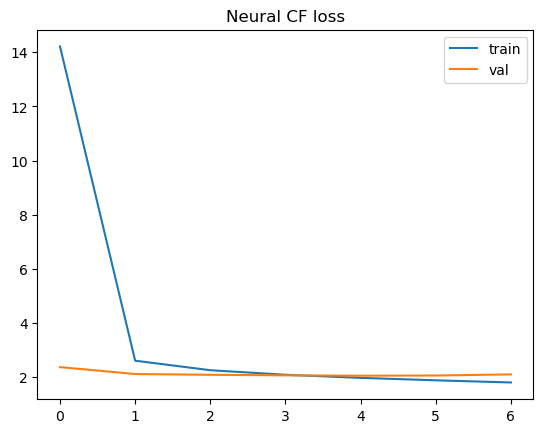

In [11]:
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("Neural CF loss")
plt.legend()
plt.show()


In [12]:
uid = int(x_test["u"].iloc[0])
seen = x_train.loc[x_train["u"] == uid, "i"].to_numpy()
cands = np.setdiff1d(np.arange(n_item), seen)
preds = dl.predict(
    (np.full((len(cands), 1), uid), cands.reshape(-1, 1)),
    verbose=0,
).ravel()
best = cands[np.argsort(-preds)[:5]]
print(anime.loc[anime["anime_id"].isin(ie.inverse_transform(best)), "name"])


2                                                Gintama°
7                                    Ginga Eiyuu Densetsu
8       Gintama Movie: Kanketsu-hen - Yorozuya yo Eien...
48                           Mushishi Special: Hihamukage
3102                                       Hashire Melos!
Name: name, dtype: object


In [13]:
dl.save("anime_ncf.keras")


# Conclusion

I sampled 200000 scored anime ratings and trained Truncated SVD and a neural collaborative filter on the same split. SVD is the classical matrix-factor baseline. The neural model learns embeddings for users and titles and predicts the score; that is the deep learning model here. RMSE is the number to watch. The neural model is saved as anime_ncf.keras.
